In [1]:
import pandas as pd
                    

D:\Anaconda_Install\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
D:\Anaconda_Install\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


In [2]:
df = pd.read_csv("Reviews.csv")
print(df.head())

   Id   ProductId          UserId                      ProfileName  \
0   1  B001E4KFG0  A3SGXH7AUHU8GW                       delmartian   
1   2  B00813GRG4  A1D87F6ZCVE5NK                           dll pa   
2   3  B000LQOCH0   ABXLMWJIXXAIN  Natalia Corres "Natalia Corres"   
3   4  B000UA0QIQ  A395BORC6FGVXV                             Karl   
4   5  B006K2ZZ7K  A1UQRSCLF8GW1T    Michael D. Bigham "M. Wassir"   

   HelpfulnessNumerator  HelpfulnessDenominator  Score        Time  \
0                     1                       1      5  1303862400   
1                     0                       0      1  1346976000   
2                     1                       1      4  1219017600   
3                     3                       3      2  1307923200   
4                     0                       0      5  1350777600   

                 Summary                                               Text  
0  Good Quality Dog Food  I have bought several of the Vitality canned d...  
1 

In [3]:
df.shape

(568454, 10)

In [4]:
df.describe

<bound method NDFrame.describe of             Id   ProductId          UserId                      ProfileName  \
0            1  B001E4KFG0  A3SGXH7AUHU8GW                       delmartian   
1            2  B00813GRG4  A1D87F6ZCVE5NK                           dll pa   
2            3  B000LQOCH0   ABXLMWJIXXAIN  Natalia Corres "Natalia Corres"   
3            4  B000UA0QIQ  A395BORC6FGVXV                             Karl   
4            5  B006K2ZZ7K  A1UQRSCLF8GW1T    Michael D. Bigham "M. Wassir"   
...        ...         ...             ...                              ...   
568449  568450  B001EO7N10  A28KG5XORO54AY                 Lettie D. Carter   
568450  568451  B003S1WTCU  A3I8AFVPEE8KI5                        R. Sawyer   
568451  568452  B004I613EE  A121AA1GQV751Z                    pksd "pk_007"   
568452  568453  B004I613EE   A3IBEVCTXKNOH          Kathy A. Welch "katwel"   
568453  568454  B001LR2CU2  A3LGQPJCZVL9UC                         srfell17   

        Helpfulne

In [5]:
df.info

<bound method DataFrame.info of             Id   ProductId          UserId                      ProfileName  \
0            1  B001E4KFG0  A3SGXH7AUHU8GW                       delmartian   
1            2  B00813GRG4  A1D87F6ZCVE5NK                           dll pa   
2            3  B000LQOCH0   ABXLMWJIXXAIN  Natalia Corres "Natalia Corres"   
3            4  B000UA0QIQ  A395BORC6FGVXV                             Karl   
4            5  B006K2ZZ7K  A1UQRSCLF8GW1T    Michael D. Bigham "M. Wassir"   
...        ...         ...             ...                              ...   
568449  568450  B001EO7N10  A28KG5XORO54AY                 Lettie D. Carter   
568450  568451  B003S1WTCU  A3I8AFVPEE8KI5                        R. Sawyer   
568451  568452  B004I613EE  A121AA1GQV751Z                    pksd "pk_007"   
568452  568453  B004I613EE   A3IBEVCTXKNOH          Kathy A. Welch "katwel"   
568453  568454  B001LR2CU2  A3LGQPJCZVL9UC                         srfell17   

        Helpfulness

In [6]:
df.isnull().sum()
df.duplicated().sum()

0

In [7]:
df["review_length"] = df["Text"].str.len()
df["review_length"].head(5)

0    263
1    190
2    509
3    219
4    140
Name: review_length, dtype: int64

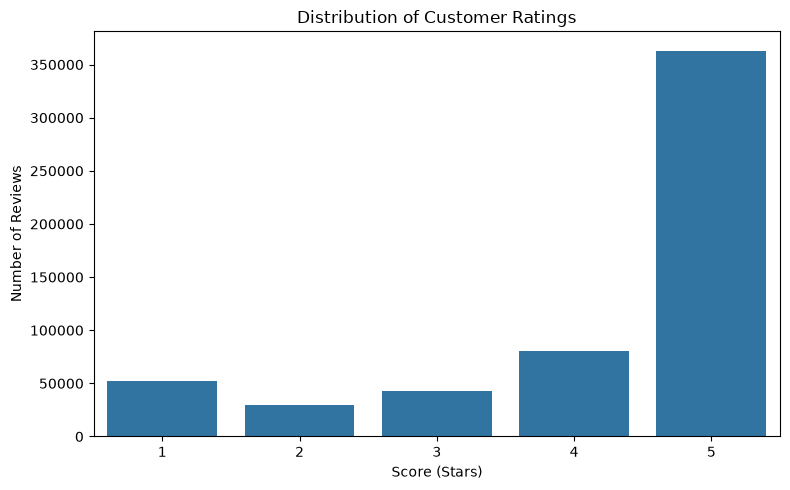

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
rating_counts = df["Score"].value_counts().sort_index()

# Plot
plt.figure(figsize=(8, 5))
sns.barplot(x=rating_counts.index, y=rating_counts.values)
plt.title("Distribution of Customer Ratings")
plt.xlabel("Score (Stars)")
plt.ylabel("Number of Reviews")
plt.xticks([0, 1, 2, 3, 4], [1, 2, 3, 4, 5])
plt.tight_layout()
plt.show()

In [9]:
!pip install nltk beautifulsoup4

In [10]:
import re
import nltk
from bs4 import BeautifulSoup
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [11]:

df['Text'] = df['Text'].str.lower()

import re
def remove_html_tags(text):
    pattern = re.compile('<.*?>')
    return pattern.sub(r'',Text)
print(df['Text'])

0         i have bought several of the vitality canned d...
1         product arrived labeled as jumbo salted peanut...
2         this is a confection that has been around a fe...
3         if you are looking for the secret ingredient i...
4         great taffy at a great price.  there was a wid...
                                ...                        
568449    great for sesame chicken..this is a good if no...
568450    i'm disappointed with the flavor. the chocolat...
568451    these stars are small, so you can give 10-15 o...
568452    these are the best treats for training and rew...
568453    i am very satisfied ,product is as advertised,...
Name: Text, Length: 568454, dtype: str


In [12]:
stop_words = set(stopwords.words('english'))

df['Text'] = df['Text'].apply(
    lambda text: ' '.join(
        word for word in text.split()
        if word not in stop_words
    ) if isinstance(text, str) else text
)
print(df['Text'].head(4))

0    bought several vitality canned dog food produc...
1    product arrived labeled jumbo salted peanuts.....
2    confection around centuries. light, pillowy ci...
3    looking secret ingredient robitussin believe f...
Name: Text, dtype: str


In [13]:
df['Text'] = df['Text'].str.replace(r'<.*?>', '', regex=True)
print(df['Text'].head(4))

0    bought several vitality canned dog food produc...
1    product arrived labeled jumbo salted peanuts.....
2    confection around centuries. light, pillowy ci...
3    looking secret ingredient robitussin believe f...
Name: Text, dtype: str


In [14]:
df['Text'] = df['Text'].apply(
    lambda text: re.sub(r'[^\w\s]', '', text)
    if isinstance(text, str) else text
)
print(df['Text'].head(3))

0    bought several vitality canned dog food produc...
1    product arrived labeled jumbo salted peanutsth...
2    confection around centuries light pillowy citr...
Name: Text, dtype: str


In [49]:
df['Text'] = df['Text'].apply(
    lambda text: word_tokenize(text) if isinstance(text, str) else text
)
print(df['Text'].head())

0    [bought, several, vitality, canned, dog, food,...
1    [product, arrived, labeled, jumbo, salted, pea...
2    [confection, around, centuries, light, pillowy...
3    [looking, secret, ingredient, robitussin, beli...
4    [great, taffy, great, price, wide, assortment,...
Name: Text, dtype: object


In [50]:
df['Text'] = df['Text'].apply(
    lambda text: ' '.join(
        lemmatizer.lemmatize(word) for word in text.split()
    ) if isinstance(text, str) else text
)
print(df['Text'].head())

0    [bought, several, vitality, canned, dog, food,...
1    [product, arrived, labeled, jumbo, salted, pea...
2    [confection, around, centuries, light, pillowy...
3    [looking, secret, ingredient, robitussin, beli...
4    [great, taffy, great, price, wide, assortment,...
Name: Text, dtype: object


In [51]:
import numpy as np
df['sentiment'] = np.where(
    df['Score'] <= 2, "Negative",
    np.where(df["Score"] == 3, "Neutral", "Positive")
)  
print(df.head(7))

   Id   ProductId          UserId                      ProfileName  \
0   1  B001E4KFG0  A3SGXH7AUHU8GW                       delmartian   
1   2  B00813GRG4  A1D87F6ZCVE5NK                           dll pa   
2   3  B000LQOCH0   ABXLMWJIXXAIN  Natalia Corres "Natalia Corres"   
3   4  B000UA0QIQ  A395BORC6FGVXV                             Karl   
4   5  B006K2ZZ7K  A1UQRSCLF8GW1T    Michael D. Bigham "M. Wassir"   
5   6  B006K2ZZ7K   ADT0SRK1MGOEU                   Twoapennything   
6   7  B006K2ZZ7K  A1SP2KVKFXXRU1                David C. Sullivan   

   HelpfulnessNumerator  HelpfulnessDenominator  Score        Time  \
0                     1                       1      5  1303862400   
1                     0                       0      1  1346976000   
2                     1                       1      4  1219017600   
3                     3                       3      2  1307923200   
4                     0                       0      5  1350777600   
5                  

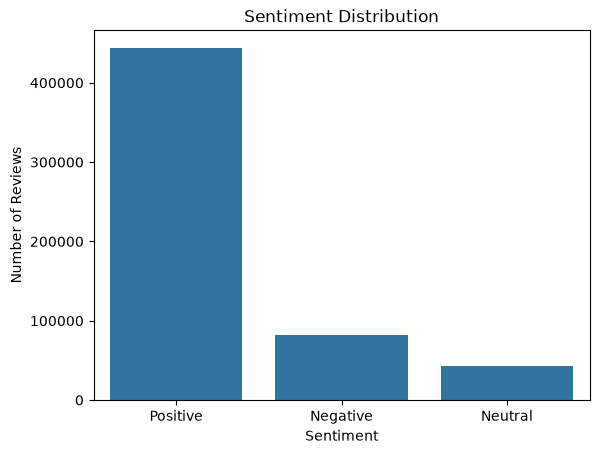

In [52]:
sns.countplot(data=df, x="sentiment")
plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

In [53]:
X = df["Text"]
y = df["sentiment"]

In [54]:
print(type(X.iloc[0]))
print(X.iloc[0])

<class 'list'>
['bought', 'several', 'vitality', 'canned', 'dog', 'food', 'products', 'found', 'good', 'quality', 'product', 'looks', 'like', 'stew', 'processed', 'meat', 'smells', 'better', 'labrador', 'finicky', 'appreciates', 'product', 'better', 'most']


In [55]:
X = df["Text"].apply(
    lambda words: " ".join(words) if isinstance(words, list) else str(words)
)
print(type(X.iloc[0]))
print(X.iloc[0])


y = df["sentiment"].apply(
    lambda words: " ".join(words) if isinstance(words, list) else str(words)
)
print(type(y.iloc[0]))
print(y.iloc[0])

<class 'str'>
bought several vitality canned dog food products found good quality product looks like stew processed meat smells better labrador finicky appreciates product better most
<class 'str'>
Positive


In [56]:
from sklearn.feature_extraction.text import CountVectorizer

cv = CountVectorizer(max_features=5000)

X_bow = cv.fit_transform(X)

print("Shape:", X_bow.shape)
print(cv.get_feature_names_out()[:20])

Shape: (568454, 5000)
['10' '100' '1000' '11' '110' '12' '120' '125' '12ounce' '12oz' '12pack'
 '13' '130' '14' '140' '15' '150' '16' '160' '16ounce']


In [57]:
print("X type:", type(X))
print("First review type:", type(X.iloc[0]))
print("First review:", X.iloc[0])

X type: <class 'pandas.Series'>
First review type: <class 'str'>
First review: bought several vitality canned dog food products found good quality product looks like stew processed meat smells better labrador finicky appreciates product better most


In [58]:
import pandas as pd

X = df["Text"].apply(
    lambda x: " ".join(map(str, x))
    if isinstance(x, list)
    else str(x) if pd.notna(x)
    else ""
)

y = df["sentiment"]

print("Review type:", type(X.iloc[0]))
print("Sample review:", X.iloc[0])

Review type: <class 'str'>
Sample review: bought several vitality canned dog food products found good quality product looks like stew processed meat smells better labrador finicky appreciates product better most


In [59]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

tfidf = TfidfVectorizer(max_features=5000)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training shape:", X_train_tfidf.shape)
print("Testing shape:", X_test_tfidf.shape)

Training shape: (454763, 5000)
Testing shape: (113691, 5000)


In [60]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Naive Bayes": MultinomialNB(),
    "Linear SVM": LinearSVC()
}
for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    print(name, "trained successfully")

Logistic Regression trained successfully
Naive Bayes trained successfully
Linear SVM trained successfully


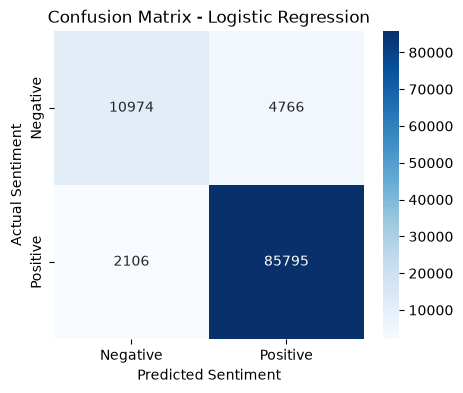

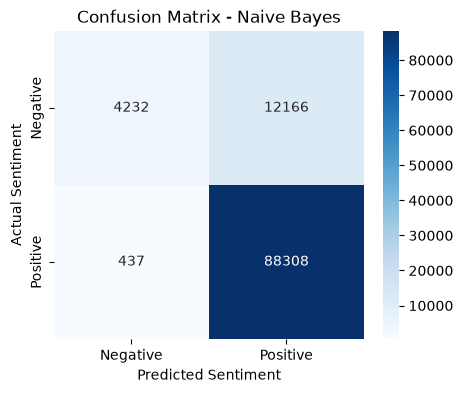

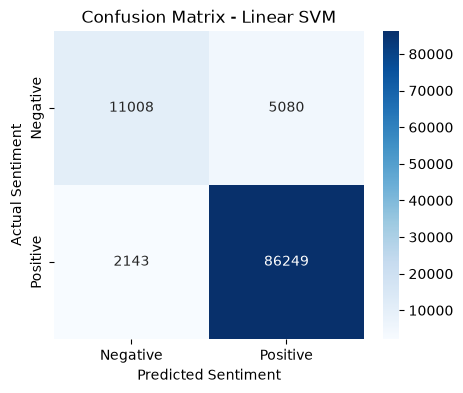

In [61]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

for name, model in models.items():
    y_pred = model.predict(X_test_tfidf)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=["Negative", "Positive"]
    )

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Negative", "Positive"],
        yticklabels=["Negative", "Positive"]
    )

    plt.xlabel("Predicted Sentiment")
    plt.ylabel("Actual Sentiment")
    plt.title(f"Confusion Matrix - {name}")
    plt.show()

In [62]:
import pandas as pd

model = models["Logistic Regression"]
y_pred = model.predict(X_test_tfidf)

error_analysis = pd.DataFrame({
    "Review": X_test,
    "Actual Sentiment": y_test,
    "Predicted Sentiment": y_pred
})

wrong_predictions = error_analysis[
    error_analysis["Actual Sentiment"] !=
    error_analysis["Predicted Sentiment"]
]

print("Total incorrect predictions:", len(wrong_predictions))
display(wrong_predictions.head(10))

Total incorrect predictions: 15355


,Review,Actual Sentiment,Predicted Sentiment
433287,really like donut shop coffe tried one nearly ...,Neutral,Positive
94630,price ryvita cheaper anywhere could buy store ...,Negative,Positive
244970,tasty like coffee mate actually like afraid fa...,Negative,Positive
275533,found coffee single serving pod pretty weak 8 ...,Neutral,Positive
258228,price could done much better ordered mints bab...,Negative,Positive
511824,like jerky products tried golden valley much s...,Neutral,Positive
117106,two retrievers ages 10 one year loved chew tor...,Negative,Positive
113859,always enjoyed product easily buy locally spec...,Neutral,Positive
292462,second soup product bought brand outstanding h...,Positive,Negative
94889,used rainbow jimmies rainbow cupcake topper ad...,Positive,Negative


In [63]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)
error_rate = 1 - accuracy

print(f"Accuracy: {accuracy:.2%}")
print(f"Error rate: {error_rate:.2%}")

Accuracy: 86.49%
Error rate: 13.51%


In [64]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = []

for name, model in models.items():
    y_pred = model.predict(X_test_tfidf)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, average="weighted", zero_division=0
        )
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score", ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.8649,0.8442,0.8649,0.8477
1,Linear SVM,0.8638,0.8432,0.8638,0.8400
2,Naive Bayes,0.8141,0.7932,0.8141,0.7560


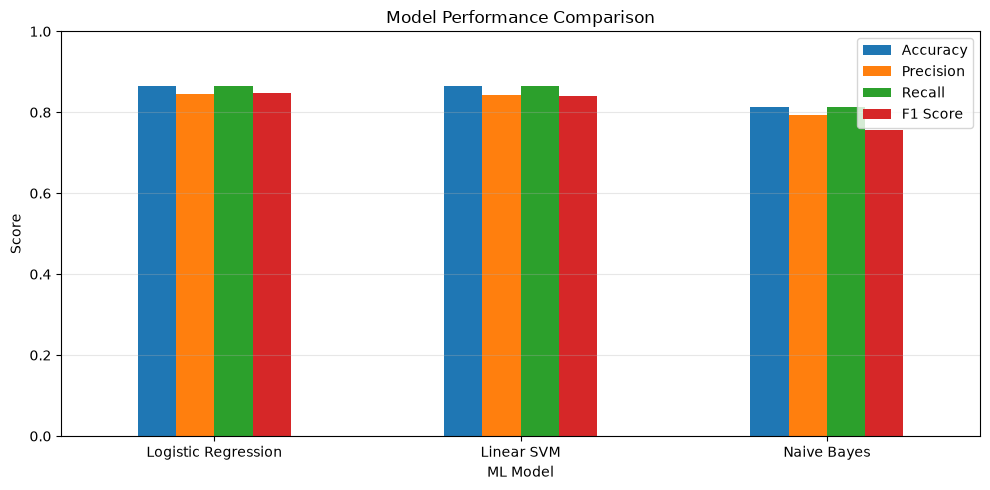

In [65]:
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1),
    rot=0
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("ML Model")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [66]:
best_model_name = results_df.iloc[0]["Model"]
best_model = models[best_model_name]

print("Best model:", best_model_name)
print("Weighted F1 Score:", round(results_df.iloc[0]["F1 Score"], 4))

Best model: Logistic Regression
Weighted F1 Score: 0.8477


In [86]:
new_reviews = [
    "The product quality is excellent and I love it",
    "Very bad experience, the product stopped working",
    "The product is okay, nothing special",
    "Amazing quality and fast delivery",
    "I am disappointed with this purchase"
]
# Convert reviews into TF-IDF features
new_reviews_tfidf = tfidf.transform(new_reviews)
# Predict sentiment using the best model
predictions = best_model.predict(new_reviews_tfidf)
# Display results
prediction_df = pd.DataFrame({
    "Customer Review": new_reviews,
    "Predicted Sentiment": predictions
})

display(prediction_df)

,Customer Review,Predicted Sentiment
0,The product quality is excellent and I love it,Positive
1,"Very bad experience, the product stopped working",Negative
2,"The product is okay, nothing special",Neutral
3,Amazing quality and fast delivery,Positive
4,I am disappointed with this purchase,Negative


In [88]:
def predict_sentiment(review):
    review_tfidf = tfidf.transform([review])
    prediction = best_model.predict(review_tfidf)[0]
    return prediction

# Test the function
review = input("Enter a customer review: ")

print("Predicted sentiment:", predict_sentiment(review))

Enter a customer review:  the product quality is good but can be better 


Predicted sentiment: Positive


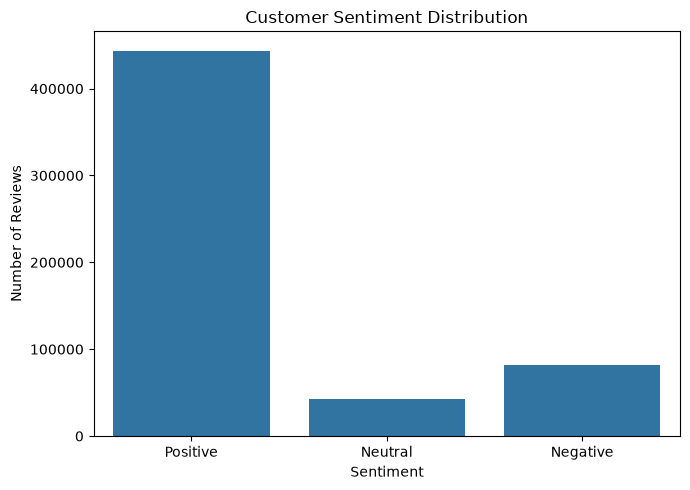

In [90]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df,x="sentiment",order=["Positive", "Neutral", "Negative"]
)
plt.title("Customer Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

In [97]:
total_reviews = len(df)

sentiment_counts = df["sentiment"].value_counts()
sentiment_percentages = (
    df["sentiment"].value_counts(normalize=True) * 100
)

print("CUSTOMER REVIEW INTELLIGENCE REPORT")
print("-" * 40)
print("Total Reviews:", total_reviews)

for sentiment in ["Positive", "Neutral", "Negative"]:
    count = sentiment_counts.get(sentiment, 0)
    percentage = sentiment_percentages.get(sentiment, 0)
    print(f"{sentiment}: {count} reviews ({percentage:.2f}%)")

print("Average Rating:", round(df["Score"].mean(), 2))

CUSTOMER REVIEW INTELLIGENCE REPORT
----------------------------------------
Total Reviews: 568454
Positive: 443777 reviews (78.07%)
Neutral: 42640 reviews (7.50%)
Negative: 82037 reviews (14.43%)
Average Rating: 4.18
